<a href="https://colab.research.google.com/github/JUAN-VILLOTA/har-smartphones-ml-grupo11/blob/main/03_reduccion_dimension.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Human Activity Recognition Using Smartphones — Grupo 11
## Parte 3. Reducción de dimensión

**Integrantes:** Juan David Villota Córdoba y Sammir Alejandro Bolaños Luna  
**Curso:** Introducción al Aprendizaje Automático — Universidad de Antioquia, 2026-2

**Qué hace este notebook:** evalúa si se puede reducir el número de características sin perder desempeño, con tres enfoques:

1. **Análisis individual de variables:** índice de Fisher (capacidad discriminante de cada característica) y correlación entre características (redundancia).
2. **Extracción lineal:** PCA.
3. **Extracción no lineal:** UMAP.

En cada caso se vuelven a evaluar **los dos mejores modelos del notebook 02: LDA y la red neuronal (MLP)**, reajustando sus hiperparámetros, porque los valores óptimos pueden cambiar en el nuevo espacio de características.

**Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todas*. Tarda entre 30 y 60 minutos; UMAP y la red neuronal son lo más lento.


## 1. Preparar las herramientas

UMAP no viene instalado por defecto; la primera celda lo instala (paquete `umap-learn`).

In [1]:
%pip install -q umap-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import io
import time
import zipfile
import tempfile
import warnings
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

## 2. Cargar los datos

La misma carga de los notebooks 01 y 02.

In [3]:
URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
with urllib.request.urlopen(URL) as respuesta:
    z = zipfile.ZipFile(io.BytesIO(respuesta.read()))
internos = [n for n in z.namelist() if n.endswith(".zip")]
if internos:
    z = zipfile.ZipFile(io.BytesIO(z.read(internos[0])))

def leer(sufijo, **kw):
    """Carga el archivo cuya ruta termina en `sufijo` (sin encabezados, separado por espacios)."""
    ruta = [n for n in z.namelist() if n.endswith(sufijo) and "Inertial" not in n][0]
    return pd.read_csv(z.open(ruta), sep=r"\s+", header=None, **kw)

features = leer("features.txt")[1].tolist()
etiquetas = leer("activity_labels.txt").set_index(0)[1].to_dict()

vistos, nombres = {}, []
for nombre in features:
    vistos[nombre] = vistos.get(nombre, 0) + 1
    nombres.append(nombre if vistos[nombre] == 1 else f"{nombre}_{vistos[nombre]}")

partes = {}
for conjunto in ["train", "test"]:
    datos = leer(f"X_{conjunto}.txt")
    datos.columns = nombres
    datos["actividad"] = leer(f"y_{conjunto}.txt")[0].map(etiquetas)
    datos["sujeto"] = leer(f"subject_{conjunto}.txt")[0]
    partes[conjunto] = datos

X, y, g = partes["train"][nombres], partes["train"]["actividad"], partes["train"]["sujeto"]
X_test, y_test = partes["test"][nombres], partes["test"]["actividad"]
N_ORIGINAL = X.shape[1]
print("Entrenamiento:", X.shape, "| Prueba:", X_test.shape, "| Voluntarios de entrenamiento:", g.nunique())

Entrenamiento: (7352, 561) | Prueba: (2947, 561) | Voluntarios de entrenamiento: 21


## 3. Configuración experimental

Las mismas reglas del notebook 02, para que las comparaciones sean justas:

- `GroupKFold` de 5 particiones por voluntario dentro del entrenamiento, con las mismas particiones para todo.
- Selección por F1 macro; resultados como media ± 2·desviación estándar de las 5 particiones.
- **Toda reducción va dentro del `Pipeline`** (filtro de variables, PCA o UMAP), así que en cada partición se ajusta solo con los datos de entrenamiento de esa partición. Si se ajustara con todas las ventanas antes de validar, la validación vería información de las ventanas que debe evaluar.
- La partición de prueba se usa una sola vez, en la sección 8.

`memory` guarda en disco las transformaciones ya calculadas (por ejemplo, UMAP de una partición), para no repetirlas cuando solo cambia un hiperparámetro del modelo.

In [4]:
CV = GroupKFold(n_splits=5)
METRICAS = {"f1": "f1_macro", "acc": "accuracy"}
CACHE = tempfile.mkdtemp()
busquedas = {}   # (modelo, técnica) -> búsqueda


def buscar(modelo, tecnica, pipeline, malla, n_jobs=-1):
    """Búsqueda en malla con GroupKFold por voluntario; elige por F1 macro."""
    gs = GridSearchCV(pipeline, malla, cv=CV, scoring=METRICAS, refit="f1",
                      return_train_score=True, n_jobs=n_jobs)
    inicio = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gs.fit(X, y, groups=g)
    busquedas[(modelo, tecnica)] = gs
    i, r = gs.best_index_, gs.cv_results_
    print(f"{modelo} + {tecnica}: {len(r['params'])} combinaciones en {time.time() - inicio:.0f} s")
    print("Mejores hiperparámetros:", {k.split('__')[-1]: v for k, v in gs.best_params_.items()})
    print(f"F1 macro validación: {r['mean_test_f1'][i]:.4f} ± {2 * r['std_test_f1'][i]:.4f}")
    return gs


def tabla(gs):
    """Una fila por combinación de hiperparámetros, ordenada por F1 de validación."""
    r = pd.DataFrame(gs.cv_results_)
    params = pd.DataFrame(list(r["params"])).rename(columns=lambda c: c.split("__")[-1])
    out = params.assign(f1_val=r["mean_test_f1"], f1_val_2std=2 * r["std_test_f1"],
                        f1_ent=r["mean_train_f1"], acc_val=r["mean_test_acc"],
                        seg_ajuste=r["mean_fit_time"], ranking=r["rank_test_f1"])
    return out.sort_values("ranking").reset_index(drop=True)


def mlp():
    return MLPClassifier(activation="relu", max_iter=500, random_state=0)


MALLA_MLP = [(16,), (32,), (64,)]

## 4. Punto de partida: los dos mejores modelos con las 561 características

Se vuelven a evaluar LDA y MLP con los hiperparámetros que ganaron en el notebook 02 (LDA: `shrinkage` = 0,0001; MLP: una capa de 32 neuronas). Es la fila de referencia contra la que se compara cada reducción.

In [5]:
buscar("LDA", "Original (561)",
       Pipeline([("escalar", StandardScaler()),
                 ("modelo", LinearDiscriminantAnalysis(solver="lsqr"))]),
       {"modelo__shrinkage": [0.0001]})
buscar("MLP", "Original (561)",
       Pipeline([("escalar", StandardScaler()), ("modelo", mlp())]),
       {"modelo__hidden_layer_sizes": [(32,)]});

LDA + Original (561): 1 combinaciones en 5 s
Mejores hiperparámetros: {'shrinkage': 0.0001}
F1 macro validación: 0.9502 ± 0.0591
MLP + Original (561): 1 combinaciones en 29 s
Mejores hiperparámetros: {'hidden_layer_sizes': (32,)}
F1 macro validación: 0.9348 ± 0.0741


## 5. Análisis individual de variables

### 5.1 Capacidad discriminante: índice de Fisher

Para cada característica se mide qué tan separadas están las seis actividades comparadas con lo dispersa que está cada una:

$$J_m = \frac{\sum_{k=1}^{6} n_k\,(\mu_{k,m} - \mu_m)^2}{\sum_{k=1}^{6} \sum_{i \in k} (x_{i,m} - \mu_{k,m})^2}$$

donde $\mu_{k,m}$ es la media de la característica $m$ en la actividad $k$, $\mu_m$ su media global y $n_k$ el número de ventanas de la actividad $k$. Arriba va la dispersión **entre** clases y abajo la dispersión **dentro** de cada clase: un $J_m$ alto indica una característica que, por sí sola, separa bien las actividades.

Es la versión para una sola característica y seis clases del criterio de Fisher $J = \mathrm{Tr}\{S_B\}/\mathrm{Tr}\{S_W\}$ de la clase 18. Este análisis es descriptivo: se calcula con las 7 352 ventanas de entrenamiento y no con la prueba.

In [6]:
def indice_fisher(X, y):
    """Índice de Fisher de cada columna: dispersión entre clases / dispersión dentro de clases."""
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    media = X.mean(axis=0)
    entre, dentro = np.zeros(X.shape[1]), np.zeros(X.shape[1])
    for c in np.unique(y):
        Xc = X[y == c]
        media_c = Xc.mean(axis=0)
        entre += len(Xc) * (media_c - media) ** 2
        dentro += ((Xc - media_c) ** 2).sum(axis=0)
    return entre / (dentro + 1e-12)


fisher = pd.Series(indice_fisher(X, y), index=nombres).sort_values(ascending=False)
print("Las 15 características más discriminantes:")
display(fisher.head(15).round(3).to_frame("Índice de Fisher"))
print("Las 10 menos discriminantes:")
display(fisher.tail(10).round(4).to_frame("Índice de Fisher"))

Las 15 características más discriminantes:


,Índice de Fisher
fBodyAccJerk-entropy()-X,25.128
tGravityAcc-mean()-X,19.985
tGravityAcc-min()-X,19.177
fBodyAccJerk-entropy()-Y,19.137
tGravityAcc-max()-X,18.164
tGravityAcc-energy()-X,17.684
fBodyBodyAccJerkMag-entropy(),16.076
tBodyAccJerkMag-entropy(),15.952
fBodyAcc-entropy()-X,15.806
tBodyAccJerk-entropy()-X,15.156


Las 10 menos discriminantes:


,Índice de Fisher
"angle(tBodyGyroJerkMean,gravityMean)",0.0051
fBodyBodyAccJerkMag-maxInds,0.0038
"angle(tBodyAccMean,gravity)",0.0035
"tBodyGyroJerk-arCoeff()-X,4",0.0026
tBodyGyroJerk-mean()-Z,0.0013
tBodyGyroJerk-mean()-Y,0.0013
"angle(tBodyAccJerkMean),gravityMean)",0.0009
tBodyAccJerk-mean()-X,0.0005
tBodyAccJerk-mean()-Y,0.0004
tBodyAccJerk-mean()-Z,0.0002


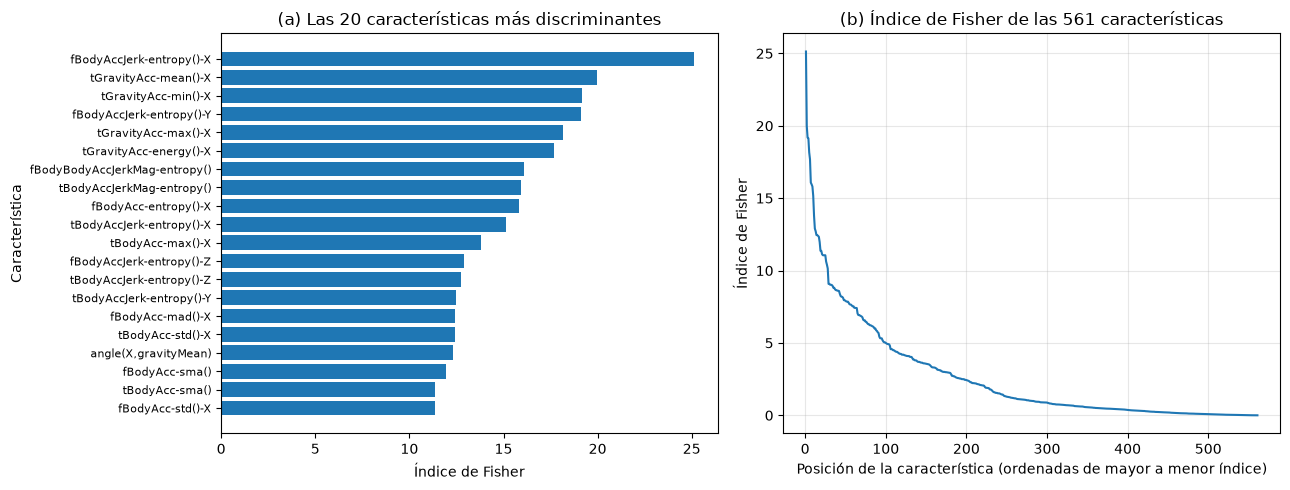

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

top = fisher.head(20).iloc[::-1]
ax[0].barh(top.index, top.values)
ax[0].set_xlabel("Índice de Fisher")
ax[0].set_ylabel("Característica")
ax[0].set_title("(a) Las 20 características más discriminantes")
ax[0].tick_params(axis="y", labelsize=8)

ax[1].plot(np.arange(1, len(fisher) + 1), fisher.values)
ax[1].set_xlabel("Posición de la característica (ordenadas de mayor a menor índice)")
ax[1].set_ylabel("Índice de Fisher")
ax[1].set_title("(b) Índice de Fisher de las 561 características")
ax[1].grid(alpha=0.3)

plt.tight_layout(); plt.savefig("fig_fisher.png", dpi=200); plt.show()

**Qué mirar:** si en los primeros lugares aparecen características de gravedad (`tGravityAcc…`) o ángulos con la gravedad (`angle(…gravityMean)`), se confirma con datos que la orientación del celular es la pista principal de la postura, como se planteó en el análisis del problema. La curva (b) muestra cuántas características aportan poca separación por sí solas.

### 5.2 Redundancia: correlación entre características

Dos características con correlación cercana a ±1 llevan casi la misma información; basta con conservar una. Se calcula la correlación de Pearson entre todos los pares de las 561 características.

Pares con |correlación| > 0.8:  23058 de 157080
Pares con |correlación| > 0.9:   8206 de 157080
Pares con |correlación| > 0.95:   2281 de 157080
Pares con |correlación| > 0.99:    207 de 157080


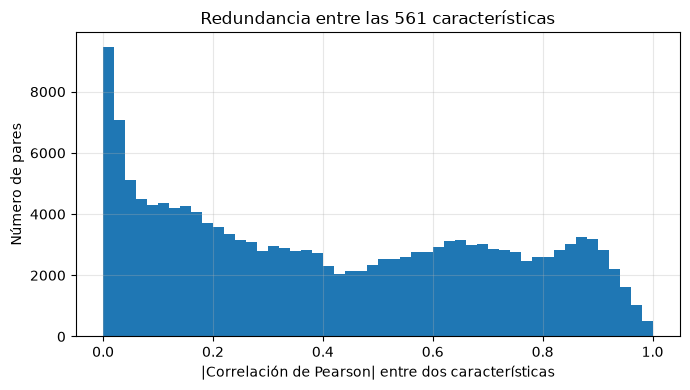

In [8]:
corr = np.abs(np.corrcoef(X.values, rowvar=False))
pares = corr[np.triu_indices_from(corr, k=1)]

for umbral in [0.80, 0.90, 0.95, 0.99]:
    print(f"Pares con |correlación| > {umbral}: {int((pares > umbral).sum()):>6} de {len(pares)}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(pares, bins=50)
ax.set_xlabel("|Correlación de Pearson| entre dos características")
ax.set_ylabel("Número de pares")
ax.set_title("Redundancia entre las 561 características")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_correlacion.png", dpi=200); plt.show()

### 5.3 Candidatas a eliminar

Se combinan los dos análisis con un filtro sencillo:

1. Se ordenan las características de mayor a menor índice de Fisher.
2. Se recorren en ese orden; una característica se **conserva** solo si su correlación absoluta con todas las ya conservadas es menor que un umbral.
3. Las que no se conservan son **candidatas a eliminar**: son redundantes con otra característica más discriminante.

Así, entre dos características casi iguales, se queda la que mejor separa las actividades.

In [9]:
class FiltroCorrelacion(BaseEstimator, TransformerMixin):
    """Conserva las características más discriminantes (Fisher) que no estén correlacionadas
    por encima de `umbral` con otra ya conservada. Se ajusta solo con los datos que recibe en fit."""

    def __init__(self, umbral=0.95):
        self.umbral = umbral

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        orden = np.argsort(-indice_fisher(X, y))
        corr = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        conservar = []
        for j in orden:
            if not conservar or corr[j, conservar].max() < self.umbral:
                conservar.append(j)
        self.columnas_ = np.sort(conservar)
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.columnas_]


resumen_filtro = []
for umbral in [0.80, 0.90, 0.95, 0.99]:
    n = len(FiltroCorrelacion(umbral).fit(X, y).columnas_)
    resumen_filtro.append({"Umbral": umbral, "Se conservan": n, "Candidatas a eliminar": N_ORIGINAL - n,
                           "% de reducción": round(100 * (1 - n / N_ORIGINAL), 1)})
pd.DataFrame(resumen_filtro)

,Umbral,Se conservan,Candidatas a eliminar,% de reducción
0,0.80,175,386,68.8
1,0.90,224,337,60.1
2,0.95,287,274,48.8
3,0.99,451,110,19.6


### 5.4 Reevaluación con las variables filtradas

El umbral de correlación se trata como un hiperparámetro más: se elige junto con los del modelo, por validación. El filtro está dentro del `Pipeline`, así que en cada partición se calcula solo con las ventanas de entrenamiento de esa partición.

In [10]:
# El filtro es rápido, así que estos Pipeline no usan memory (caché)
filtro_lda = Pipeline([("escalar", StandardScaler()), ("reducir", FiltroCorrelacion()),
                       ("modelo", LinearDiscriminantAnalysis(solver="lsqr"))])
buscar("LDA", "Filtro Fisher + correlación", filtro_lda,
       {"reducir__umbral": [0.80, 0.90, 0.95, 0.99], "modelo__shrinkage": [0.0001, 0.01, 0.1]})
display(tabla(busquedas[("LDA", "Filtro Fisher + correlación")]).head(6))

filtro_mlp = Pipeline([("escalar", StandardScaler()), ("reducir", FiltroCorrelacion()),
                       ("modelo", mlp())])
buscar("MLP", "Filtro Fisher + correlación", filtro_mlp,
       {"reducir__umbral": [0.90, 0.95], "modelo__hidden_layer_sizes": MALLA_MLP})
display(tabla(busquedas[("MLP", "Filtro Fisher + correlación")]))

LDA + Filtro Fisher + correlación: 12 combinaciones en 10 s
Mejores hiperparámetros: {'shrinkage': 0.0001, 'umbral': 0.99}
F1 macro validación: 0.9498 ± 0.0610


,shrinkage,umbral,f1_val,f1_val_2std,f1_ent,acc_val,seg_ajuste,ranking
0,0.0001,0.99,0.949828,0.060980,0.987750,0.949820,1.344107,1
1,0.0100,0.99,0.942847,0.063489,0.985388,0.942266,1.011734,2
2,0.0001,0.95,0.939715,0.066730,0.982886,0.939605,0.822919,3
3,0.0100,0.95,0.934300,0.066685,0.981376,0.933929,1.073601,4
4,0.1000,0.99,0.933025,0.081763,0.978611,0.933136,0.916474,5
5,0.1000,0.95,0.932162,0.081575,0.973406,0.932033,0.840275,6


MLP + Filtro Fisher + correlación: 6 combinaciones en 46 s
Mejores hiperparámetros: {'hidden_layer_sizes': (64,), 'umbral': 0.9}
F1 macro validación: 0.9316 ± 0.0585


,hidden_layer_sizes,umbral,f1_val,f1_val_2std,f1_ent,acc_val,seg_ajuste,ranking
0,"(64,)",0.90,0.931572,0.058484,1.0,0.931284,11.864667,1
1,"(32,)",0.95,0.929936,0.077537,1.0,0.929966,15.499351,2
2,"(64,)",0.95,0.929412,0.079028,1.0,0.929943,9.353747,3
3,"(32,)",0.90,0.928659,0.066541,1.0,0.928453,13.810694,4
4,"(16,)",0.90,0.919395,0.076924,1.0,0.919150,14.942825,5
5,"(16,)",0.95,0.918565,0.100905,1.0,0.920014,19.131102,6


## 6. Extracción lineal: PCA

PCA crea nuevas variables (componentes principales) que son combinaciones lineales de las 561 originales. La primera componente recoge la dirección de mayor varianza de los datos, la segunda la siguiente, y así sucesivamente. Como hay tanta redundancia, pocas componentes deberían conservar casi toda la información.

### 6.1 Criterio para elegir el número de componentes

**Criterio: conservar el 95 % de la varianza explicada.** Es un criterio estándar, se decide antes de mirar el desempeño de los modelos y es fácil de justificar. La curva de varianza acumulada muestra cuántas componentes se necesitan.

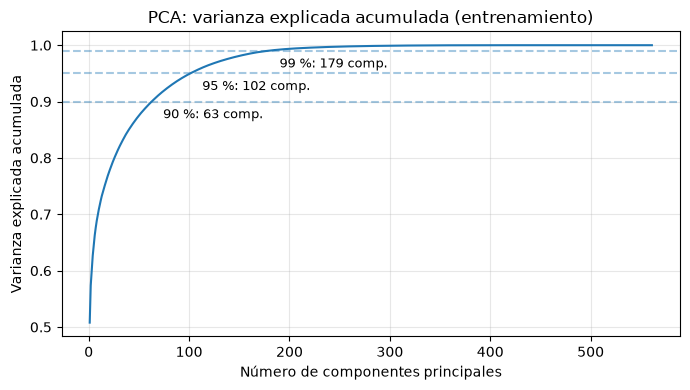

90 % de la varianza: 63 componentes (88.8 % de reducción)
95 % de la varianza: 102 componentes (81.8 % de reducción)
99 % de la varianza: 179 componentes (68.1 % de reducción)


In [11]:
pca_total = PCA().fit(StandardScaler().fit_transform(X))
acumulada = np.cumsum(pca_total.explained_variance_ratio_)
k = {p: int(np.searchsorted(acumulada, p) + 1) for p in [0.90, 0.95, 0.99]}

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(acumulada) + 1), acumulada)
for p, n in k.items():
    ax.axhline(p, linestyle="--", alpha=0.4)
    ax.annotate(f"{int(p * 100)} %: {n} comp.", (n, p), textcoords="offset points", xytext=(8, -12), fontsize=9)
ax.set_xlabel("Número de componentes principales")
ax.set_ylabel("Varianza explicada acumulada")
ax.set_title("PCA: varianza explicada acumulada (entrenamiento)")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_pca_varianza.png", dpi=200); plt.show()

for p, n in k.items():
    print(f"{int(p * 100)} % de la varianza: {n} componentes ({100 * (1 - n / N_ORIGINAL):.1f} % de reducción)")

### 6.2 Comprobación: desempeño de LDA según el número de componentes

Para verificar que el criterio del 95 % es razonable, se evalúa LDA (que es rápido) con distintos números de componentes. Si la curva ya está estable cerca del número que da el criterio, la elección queda respaldada.

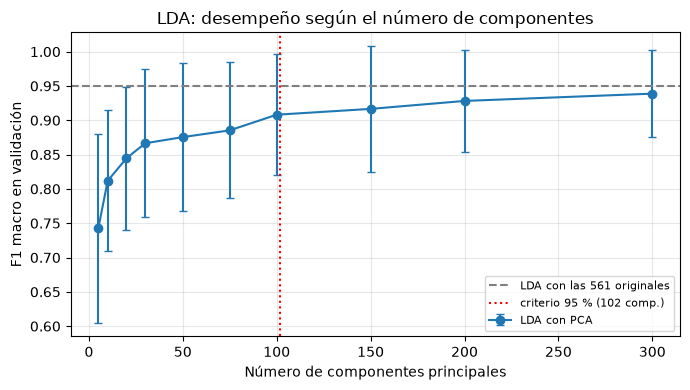

,componentes,f1,f1_2std
0,5,0.7428,0.1376
1,10,0.8118,0.1029
2,20,0.8447,0.1042
3,30,0.8665,0.1079
4,50,0.8755,0.1074
5,75,0.8854,0.0993
6,100,0.9081,0.0879
7,150,0.9166,0.0914
8,200,0.9282,0.0744
9,300,0.9388,0.0637


In [12]:
curva = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for n in [5, 10, 20, 30, 50, 75, 100, 150, 200, 300]:
        pipe = Pipeline([("escalar", StandardScaler()), ("reducir", PCA(n_components=n)),
                         ("modelo", LinearDiscriminantAnalysis(solver="lsqr", shrinkage=0.0001))])
        s = cross_validate(pipe, X, y, cv=CV, groups=g, scoring="f1_macro", n_jobs=-1)
        curva.append({"componentes": n, "f1": s["test_score"].mean(), "f1_2std": 2 * s["test_score"].std()})
curva = pd.DataFrame(curva)

ref = busquedas[("LDA", "Original (561)")]
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(curva["componentes"], curva["f1"], yerr=curva["f1_2std"], marker="o", capsize=3, label="LDA con PCA")
ax.axhline(ref.best_score_, color="gray", linestyle="--", label="LDA con las 561 originales")
ax.axvline(k[0.95], color="red", linestyle=":", label=f"criterio 95 % ({k[0.95]} comp.)")
ax.set_xlabel("Número de componentes principales")
ax.set_ylabel("F1 macro en validación")
ax.set_title("LDA: desempeño según el número de componentes")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_pca_componentes.png", dpi=200); plt.show()
curva.round(4)

### 6.3 Reevaluación con PCA (95 % de la varianza)

`PCA(n_components=0.95)` elige en cada partición el número de componentes que conserva el 95 % de la varianza de esa partición. Los hiperparámetros de los modelos se reajustan.

In [13]:
pca_lda = Pipeline([("escalar", StandardScaler()), ("reducir", PCA(n_components=0.95)),
                    ("modelo", LinearDiscriminantAnalysis(solver="lsqr"))], memory=CACHE)
buscar("LDA", "PCA (95 % varianza)", pca_lda, {"modelo__shrinkage": [0.0001, 0.001, 0.01, 0.1, 0.3]})
display(tabla(busquedas[("LDA", "PCA (95 % varianza)")]))

pca_mlp = Pipeline([("escalar", StandardScaler()), ("reducir", PCA(n_components=0.95)),
                    ("modelo", mlp())], memory=CACHE)
buscar("MLP", "PCA (95 % varianza)", pca_mlp, {"modelo__hidden_layer_sizes": MALLA_MLP})
display(tabla(busquedas[("MLP", "PCA (95 % varianza)")]))

LDA + PCA (95 % varianza): 5 combinaciones en 3 s
Mejores hiperparámetros: {'shrinkage': 0.0001}
F1 macro validación: 0.9090 ± 0.0882


,shrinkage,f1_val,f1_val_2std,f1_ent,acc_val,seg_ajuste,ranking
0,0.0001,0.908957,0.088227,0.952382,0.909135,1.317273,1
1,0.0010,0.908957,0.088227,0.952338,0.909135,1.266545,1
2,0.0100,0.908096,0.088797,0.951993,0.908310,0.753832,3
3,0.1000,0.904496,0.087341,0.946557,0.904933,0.330111,4
4,0.3000,0.893401,0.093141,0.933755,0.894327,0.312303,5


MLP + PCA (95 % varianza): 3 combinaciones en 13 s
Mejores hiperparámetros: {'hidden_layer_sizes': (64,)}
F1 macro validación: 0.9151 ± 0.0760


,hidden_layer_sizes,f1_val,f1_val_2std,f1_ent,acc_val,seg_ajuste,ranking
0,"(64,)",0.915112,0.075989,1.0,0.916055,4.891825,1
1,"(32,)",0.909356,0.079766,1.0,0.909929,5.659602,2
2,"(16,)",0.906218,0.092777,1.0,0.907459,6.242844,3


## 7. Extracción no lineal: UMAP

UMAP construye un mapa de pocas dimensiones tratando de que las ventanas que eran vecinas en las 561 dimensiones sigan siendo vecinas. A diferencia de PCA, puede capturar relaciones no lineales. Se usa sin etiquetas (no supervisado), igual que PCA, y con sus valores por defecto de vecindad (`n_neighbors` = 15, `min_dist` = 0,1).

### 7.1 Visualización en dos dimensiones

Solo para mirar la estructura de los datos, no para evaluar.

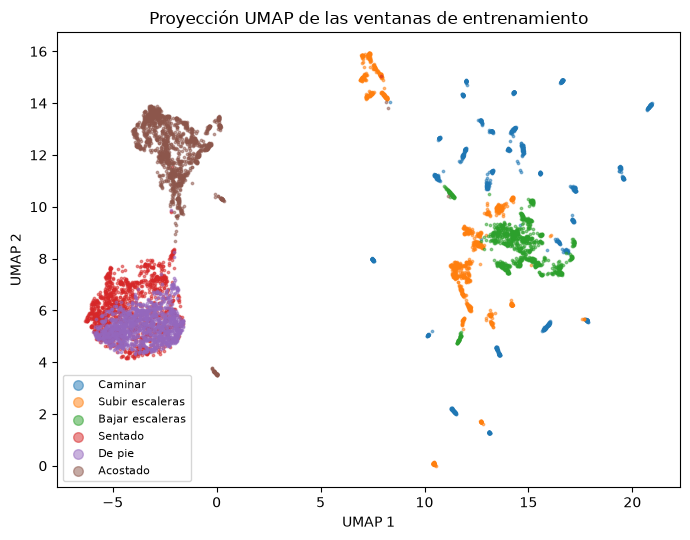

In [14]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    Z = umap.UMAP(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(X))

orden = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
nombres_es = {"WALKING": "Caminar", "WALKING_UPSTAIRS": "Subir escaleras", "WALKING_DOWNSTAIRS": "Bajar escaleras",
              "SITTING": "Sentado", "STANDING": "De pie", "LAYING": "Acostado"}

fig, ax = plt.subplots(figsize=(7, 5.5))
for act in orden:
    m = y.values == act
    ax.scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.5, label=nombres_es[act])
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("Proyección UMAP de las ventanas de entrenamiento")
ax.legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.savefig("fig_umap_2d.png", dpi=200); plt.show()

### 7.2 UMAP sin etiquetas dentro del Pipeline

Dentro de un `Pipeline`, scikit-learn le entrega las etiquetas `y` a cada paso. Si UMAP las recibe, se vuelve **supervisado**: usa la actividad para construir el mapa. Para compararlo en igualdad de condiciones con PCA, que no usa etiquetas, se envuelve UMAP en una clase que las ignora.

Esta búsqueda se ejecuta sin paralelizar (`n_jobs=1`) para que la caché guarde cada UMAP calculado y no se repita cuando solo cambia un hiperparámetro del modelo.

### 7.3 Criterio para elegir el número de componentes

UMAP no tiene un equivalente a la varianza explicada, así que el número de componentes se elige **por validación**: se prueba como un hiperparámetro más (2, 5, 10 y 20 componentes), junto con los del modelo. UMAP va dentro del `Pipeline`, así que en cada partición se ajusta solo con las ventanas de entrenamiento de esa partición.

In [15]:
class UMAPNoSupervisado(BaseEstimator, TransformerMixin):
    """UMAP que ignora las etiquetas, aunque el Pipeline se las entregue."""

    def __init__(self, n_components=2, n_neighbors=15, min_dist=0.1, random_state=0):
        self.n_components = n_components
        self.n_neighbors = n_neighbors
        self.min_dist = min_dist
        self.random_state = random_state

    def fit(self, X, y=None):
        self.umap_ = umap.UMAP(n_components=self.n_components, n_neighbors=self.n_neighbors,
                               min_dist=self.min_dist, random_state=self.random_state).fit(X)
        return self

    def transform(self, X):
        return self.umap_.transform(X)


umap_lda = Pipeline([("escalar", StandardScaler()), ("reducir", UMAPNoSupervisado()),
                     ("modelo", LinearDiscriminantAnalysis(solver="lsqr"))], memory=CACHE)
buscar("LDA", "UMAP", umap_lda,
       {"reducir__n_components": [2, 5, 10, 20], "modelo__shrinkage": [0.0001, 0.1]}, n_jobs=1)
display(tabla(busquedas[("LDA", "UMAP")]))

LDA + UMAP: 8 combinaciones en 419 s
Mejores hiperparámetros: {'shrinkage': 0.0001, 'n_components': 20}
F1 macro validación: 0.8169 ± 0.0626


,shrinkage,n_components,f1_val,f1_val_2std,f1_ent,acc_val,seg_ajuste,ranking
0,0.0001,20,0.816930,0.062647,0.864713,0.818436,14.144653,1
1,0.1000,20,0.795296,0.089276,0.837440,0.798754,0.203886,2
2,0.1000,10,0.784979,0.071503,0.824499,0.788756,0.216282,3
3,0.0001,10,0.781090,0.065841,0.832205,0.785224,12.765824,4
4,0.1000,5,0.764890,0.072306,0.786697,0.770337,0.215845,5
5,0.0001,5,0.760870,0.070728,0.788674,0.765949,11.296548,6
6,0.0001,2,0.646956,0.100398,0.673885,0.676574,32.632136,7
7,0.1000,2,0.645780,0.099992,0.675229,0.675940,0.217691,8


In [16]:
umap_mlp = Pipeline([("escalar", StandardScaler()), ("reducir", UMAPNoSupervisado()),
                     ("modelo", mlp())], memory=CACHE)
buscar("MLP", "UMAP", umap_mlp,
       {"reducir__n_components": [5, 10, 20], "modelo__hidden_layer_sizes": MALLA_MLP}, n_jobs=1)
display(tabla(busquedas[("MLP", "UMAP")]))

MLP + UMAP: 9 combinaciones en 299 s
Mejores hiperparámetros: {'hidden_layer_sizes': (16,), 'n_components': 10}
F1 macro validación: 0.8536 ± 0.0741


,hidden_layer_sizes,n_components,f1_val,f1_val_2std,f1_ent,acc_val,seg_ajuste,ranking
0,"(16,)",10,0.853580,0.074083,0.931494,0.856006,5.841962,1
1,"(32,)",10,0.852419,0.083949,0.939691,0.854894,5.009375,2
2,"(16,)",20,0.851853,0.063926,0.928268,0.853857,5.592075,3
3,"(32,)",20,0.851437,0.067737,0.935083,0.853634,4.627450,4
4,"(64,)",10,0.851056,0.074857,0.936767,0.853794,4.600056,5
5,"(64,)",20,0.849130,0.064330,0.931813,0.850957,4.175720,6
6,"(64,)",5,0.841682,0.068680,0.926092,0.844773,5.636237,7
7,"(32,)",5,0.835717,0.076799,0.927250,0.839466,5.762106,8
8,"(16,)",5,0.822790,0.063521,0.890678,0.827799,5.068495,9


## 8. Porcentaje de reducción vs desempeño

Para cada modelo y técnica: número de características con que queda el modelo final (reentrenado con todo el entrenamiento), porcentaje de reducción, desempeño en validación (media ± 2·desv. est.) y, una sola vez, en la partición de prueba.

In [17]:
def n_caracteristicas(gs):
    """Número de características que recibe el modelo final."""
    paso = gs.best_estimator_.named_steps.get("reducir")
    if paso is None:
        return N_ORIGINAL
    if isinstance(paso, FiltroCorrelacion):
        return len(paso.columnas_)
    if isinstance(paso, PCA):
        return int(paso.n_components_)
    return int(paso.n_components)   # UMAP


filas = []
for (modelo, tecnica), gs in busquedas.items():
    i, r = gs.best_index_, gs.cv_results_
    n = n_caracteristicas(gs)
    pred = gs.best_estimator_.predict(X_test)
    filas.append({
        "Modelo": modelo, "Técnica": tecnica, "Características": n,
        "% reducción": 100 * (1 - n / N_ORIGINAL),
        "Hiperparámetros": {k.split("__")[-1]: v for k, v in gs.best_params_.items()},
        "F1 validación": r["mean_test_f1"][i], "±2std": 2 * r["std_test_f1"][i],
        "Exactitud validación": r["mean_test_acc"][i],
        "F1 prueba": f1_score(y_test, pred, average="macro"),
        "Exactitud prueba": accuracy_score(y_test, pred),
        "Seg. por ajuste": r["mean_fit_time"][i],
    })
resultados = pd.DataFrame(filas)
resultados.to_csv("resultados_reduccion.csv", index=False)
resultados.round(4)

,Modelo,Técnica,Características,% reducción,Hiperparámetros,F1 validación,±2std,Exactitud validación,F1 prueba,Exactitud prueba,Seg. por ajuste
0,LDA,Original (561),561,0.0000,{'shrinkage': 0.0001},0.9502,0.0591,0.9499,0.9633,0.9630,0.7420
1,MLP,Original (561),561,0.0000,"{'hidden_layer_sizes': (32,)}",0.9348,0.0741,0.9353,0.9516,0.9511,13.0945
2,LDA,Filtro Fisher + correlación,451,19.6078,"{'shrinkage': 0.0001, 'umbral': 0.99}",0.9498,0.0610,0.9498,0.9597,0.9596,1.3441
3,MLP,Filtro Fisher + correlación,224,60.0713,"{'hidden_layer_sizes': (64,), 'umbral': 0.9}",0.9316,0.0585,0.9313,0.9348,0.9355,11.8647
4,LDA,PCA (95 % varianza),102,81.8182,{'shrinkage': 0.0001},0.9090,0.0882,0.9091,0.9282,0.9294,1.3173
5,MLP,PCA (95 % varianza),102,81.8182,"{'hidden_layer_sizes': (64,)}",0.9151,0.0760,0.9161,0.9304,0.9311,4.8918
6,LDA,UMAP,20,96.4349,"{'shrinkage': 0.0001, 'n_components': 20}",0.8169,0.0626,0.8184,0.8234,0.8252,14.1447
7,MLP,UMAP,10,98.2175,"{'hidden_layer_sizes': (16,), 'n_components': 10}",0.8536,0.0741,0.8560,0.8574,0.8609,5.8420


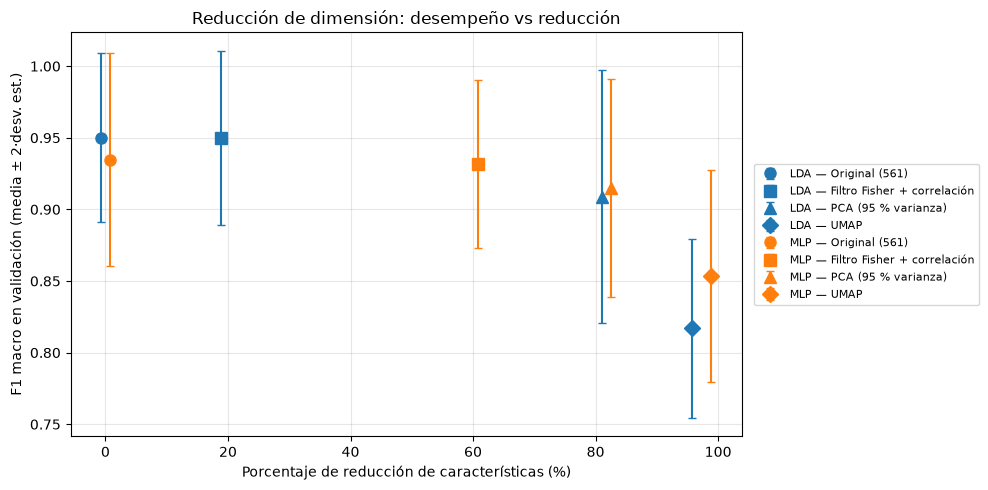

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
marcadores = {"Original (561)": "o", "Filtro Fisher + correlación": "s", "PCA (95 % varianza)": "^", "UMAP": "D"}
desplazamiento = {"LDA": -0.7, "MLP": 0.7}   # separa un poco los puntos de los dos modelos
for modelo, d in resultados.groupby("Modelo"):
    color = None
    for _, f in d.iterrows():
        linea = ax.errorbar(f["% reducción"] + desplazamiento.get(modelo, 0), f["F1 validación"], yerr=f["±2std"],
                            fmt=marcadores[f["Técnica"]], capsize=3, markersize=8, color=color,
                            label=f"{modelo} — {f['Técnica']}")
        color = linea[0].get_color()
ax.set_xlabel("Porcentaje de reducción de características (%)")
ax.set_ylabel("F1 macro en validación (media ± 2·desv. est.)")
ax.set_title("Reducción de dimensión: desempeño vs reducción")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.savefig("fig_reduccion.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. Discusión y conclusiones

*Completar después de ejecutar, con los números de las secciones 5 a 8:*

- **Análisis individual:** ¿cuáles fueron las características más discriminantes? ¿Son de gravedad o de ángulos? ¿Cuántas resultaron candidatas a eliminar con el umbral elegido?
- **PCA:** ¿cuántas componentes da el criterio del 95 %? ¿Qué porcentaje de reducción es? ¿Cuánto cambia el F1 de cada modelo frente a las 561 originales? ¿Los intervalos se superponen?
- **UMAP:** ¿cuántas componentes eligió la validación? ¿Rinde mejor o peor que PCA y por qué podría ser?
- **Mejor opción:** ¿qué técnica logra la mayor reducción sin perder desempeño de forma apreciable (intervalos superpuestos con el original)?
- **Estado del arte:** los trabajos revisados (Anguita et al., Xu et al., Pang et al.) usan las 561 características sin selección; ¿qué aporta mostrar que se puede reducir la dimensión manteniendo un desempeño comparable (96 % aprox.)?